Test the slab model with 2 islands. Fig.15 (e):
$$
\begin{align*}
&m_1=m_2=1\;,\;n_1=-n_2=1\\
&\delta_1=\delta_2 =0.05\\
&\iota'=4.0
\end{align*}
$$

In [1]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
from fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot, FixedPoint, Manifold
import matplotlib.pyplot as plt

#### Create the magnetic field:

In [2]:
config_id = 115

field = SlabBfieldTwoPert(
    m1=1,
    n1=1,
    delta1=0.05,
    m2=1,
    n2=-1,
    delta2=0.05,
    iota_prime=4.0,
    x0=1.0,
)

xs1 = field.x0 + field.n1 / (field.iota_prime * field.m1)
xs2 = field.x0 + field.n2 / (field.iota_prime * field.m2)

print("The islands will be situated at x_s =", xs1, xs2)

The islands will be situated at x_s = 1.25 0.75


#### Create the map:

In [3]:
map = ToroidalBfieldSection(field, domain=[(0, 2), (0, 2*np.pi)])

#### Create Poincaré plot:

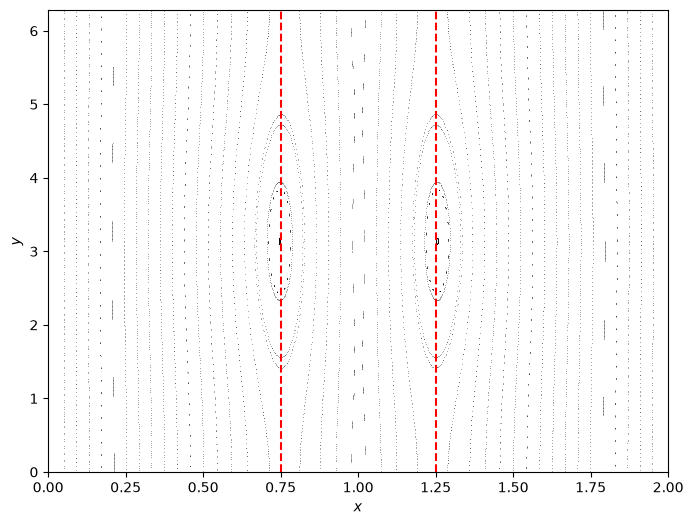

In [4]:
poincare_dir = Path("../../num_results_loc/poincare_plots")
path_poincare = poincare_dir / f"pplot_{config_id}.npz"
with np.load(path_poincare) as data:
    hits = data["hits"].copy()

# Plot directly in (x,y) coordinates
fig, ax = plt.subplots(figsize=(8, 6))

for traj in hits:
    ax.scatter(traj[:, 0], traj[:, 1], color="black", marker=".", s=0.5, lw=0)


ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_xlim(0, 2)
ax.set_ylim(0, 2*np.pi)

ax.axvline(
    xs1,
    linestyle="--",
    label=rf"$x_s1={xs1:.3f}$",
    color="r"
)
ax.axvline(
    xs2,
    linestyle="--",
    label=rf"$x_s2={xs2:.3f}$",
    color="r"
)
plt.show()

#### Find manifolds

In [42]:
fp1 = FixedPoint(map)
fp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([xs1, 6.28]), method="scipy.root")   

fp2 = FixedPoint(map)
fp2.find(t=1, guess = np.array([1.25, 6.28]), method="scipy.root")  

fp3 = FixedPoint(map)
fp3.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.7542, 2*np.pi]), method="scipy.root") 

fp4 = FixedPoint(map)
fp4.find(t=1, guess = np.array([0.7542, 6.28]), method="scipy.root") 

ofp1 = FixedPoint(map)
ofp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([xs1, 3]), method="scipy.root")

ofp2 = FixedPoint(map)
ofp2.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 3]), method="scipy.root")

In [43]:
fp3.coords, fp4.coords

(array([[7.54186127e-01, 1.01172404e-11],
        [7.54186127e-01, 1.25797150e-10]]),
 array([[0.75418613, 6.28318531],
        [0.75418613, 6.28318531]]))

(<Figure size 800x600 with 1 Axes>, <Axes: >)

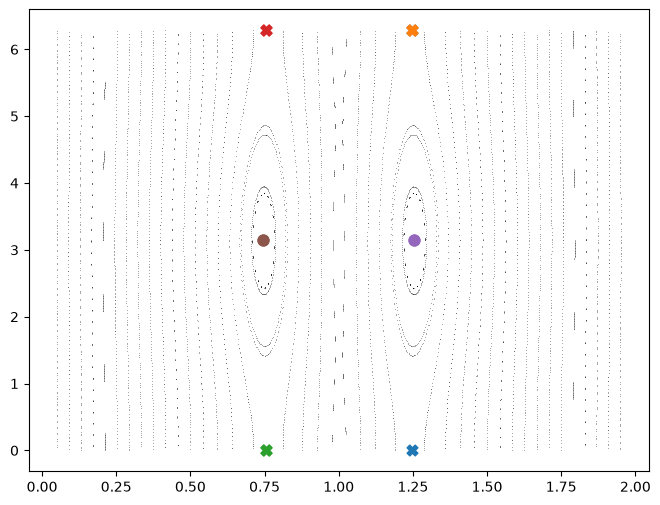

In [44]:
fig, ax = plt.subplots(figsize=(8, 6))
for traj in hits:
    ax.scatter(traj[:, 0], traj[:, 1], color="black", marker=".", s=0.5, lw=0)
fp1.plot(fig=fig, ax=ax, s=60, plottype=None)
fp2.plot(fig=fig, ax=ax, s=60, plottype=None)
fp3.plot(fig=fig, ax=ax, s=60, plottype=None)
fp4.plot(fig=fig, ax=ax, s=60, plottype=None)
ofp1.plot(fig=fig, ax=ax, s=60, plottype=None)
ofp2.plot(fig=fig, ax=ax, s=60, plottype=None)